# Geometry-normalized velocity refinement

**Question:** Does the trained residual model reduce both velocity error and independently forwarded travel-time error on unseen geology and acquisition geometry?

**Proposed method exercise** · Prerequisites: first-arrival tomography, dimensional analysis, grouped data splits and paired errors. **Time:** 35–45 minutes.

This notebook applies the frozen GPU-trained checkpoint to deterministic held-out synthetic surveys. It runs the model and a validation-selected regularized ray inversion on identical noisy arrivals. It does not retune on held-out data or claim field performance.

## Objectives

- Derive the residual feature units from the straight-ray travel-time equation.
- Reconstruct the declared non-overlapping cohorts and inspect their acquisition geometry.
- Apply the saved model and the regularized inversion to identical observations.
- Compare velocity and independent travel-time errors and interpret a negative result.

## Setup

Install the exact analysis pins and CPU PyTorch from its official index:

```bash
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8 torch==2.14.0 --extra-index-url https://download.pytorch.org/whl/cpu
```

Run `scripts/setup.ps1 -Notebooks` (or `scripts/setup.sh --notebooks`) for the reproducible environment. Inference uses CPU. To reproduce the 40-epoch CUDA training, also run `scripts/setup.ps1 -Gpu` and `python data-pipeline/velocity_physics_refinement.py --output <new-directory> --device cuda`.

Record the analysis package versions before opening any experiment artifact.

In [1]:
# Record package versions and load the product pipeline.
from importlib.metadata import version
import hashlib
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

root = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data-pipeline").is_dir()), None)
assert root is not None, "Run from the repository tree"
sys.path.insert(0, str(root / "data-pipeline"))
import velocity_physics_refinement as experiment
import velocity_validation as inverse

print({name: version(name) for name in ("numpy", "scipy", "matplotlib", "torch")})

{'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8', 'torch': '2.14.0+cpu'}


## Data

The pipeline generates synthetic surveys from fixed velocity families and seeds; no third-party data are downloaded. The joint-shift cohort contains 160 new fault and salt realizations with acquisition layout C. Partitions use disjoint seeds and are recorded in the receipt. OpenFWI is cited as a public benchmark reference, but its data are neither loaded nor redistributed.

This lesson uses the checkpoint in `models/experimental/m12-physics-cuda-20261004/`. The next cell verifies its hashes and frozen manifests, then regenerates the held-out inputs.

Validate the checkpoint hash and frozen manifests before regenerating the surveys.

In [2]:
# Verify hashes and recreate the synthetic survey groups.
receipt_dir = root / "models/experimental/m12-physics-cuda-20261004"
receipt = json.loads((receipt_dir / "receipt.json").read_text(encoding="utf-8"))
checkpoint_path = receipt_dir / receipt["checkpoint"]
assert hashlib.sha256(checkpoint_path.read_bytes()).hexdigest() == receipt["checkpoint_sha256"]
source_hash = inverse.sha256_bytes(Path(experiment.__file__).read_bytes())
assert receipt["code_sha256"] in {source_hash, experiment.LEGACY_V2_TRAINING_SOURCE_SHA256}
assert inverse.sha256_bytes(Path(inverse.__file__).read_bytes()) == receipt["operator_code_sha256"]

ops = inverse.operators()
validation = experiment.make_cohort("validation", ops)
test_names = ("id_test", "family_only", "acquisition_only", "joint_ood")
cohorts = {name: experiment.make_cohort(name, ops) for name in test_names}
for name, cohort in (("validation", validation), *cohorts.items()):
    assert cohort["records"] == receipt["split_manifests"][name]
    assert cohort["manifest_sha256"] == receipt["split_hashes"][name]
print({name: len(cohort["records"]) for name, cohort in cohorts.items()})

{'id_test': 160, 'family_only': 80, 'acquisition_only': 80, 'joint_ood': 160}


## Method

For ray `r`, the discretized straight-ray equation is `t_r = Σ_j A_rj s_j + ε_r`, with path lengths `A_rj` in metres and slowness `s_j = 1/v_j` in seconds per metre. The reference is `s₀`; the residual is `r_t = t_obs − A s₀` in seconds. A physically dimensioned first-order feature is

`δs_r = r_t,r / L_r`, with `L_r = Σ_j A_rj` (s/m),

`h_j = Σ_r A_rj δs_r / c_j`, with `c_j = Σ_r A_rj` (s/m),

`x_j = −h_j v₀,j² / 400`, a dimensionless velocity-update feature. A second channel records normalized ray coverage. Cells with zero coverage get a zero feature and remain explicitly unsupported.

The residual CNN is bounded to 1,400–4,000 m/s and initialized to reproduce the reference model. Training uses 800 training and 160 validation realizations; validation selects the epoch and classical regularization. Untouched tests contain 160 ID, 80 family-only, 80 acquisition-only and 160 joint-shift realizations. Both methods see each test realization's same noisy picks. The independent oracle forwards each returned model.

Compute the dimensionally normalized feature for one held-out survey and inspect its coverage.

In [3]:
# Compute the normalized feature for one held-out realization.
joint = cohorts["joint_ood"]
feature = experiment.input_features(joint["observed"][0], ops["C"]["cell"])
print({"shape": feature.shape, "unsupported_cells": int(np.count_nonzero(feature[1] == 0)),
       "coverage_max": float(feature[1].max())})

{'shape': (2, 16, 16), 'unsupported_cells': 5, 'coverage_max': 1.0}


## Comparison

The reference is a regularized straight-ray inversion whose weight is selected using separate validation data. Both methods receive the same noisy picks. Velocity error uses synthetic truth; travel-time error is recomputed with an independent bilinear quadrature operator.

Göppel, Frikel and Haltmeier formulate data-proximal null-space networks for limited-view tomography. This residual CNN does not reproduce that architecture. OpenFWI is a full-waveform benchmark, not the source of these first-arrival data.

Select regularization on validation only, then run both methods on the held-out cohorts.

In [4]:
# Select the parameter on validation and score both methods on each test group.
selected_lambda, candidates = inverse.select_classical(validation, ops)
experiment.verify_classical_selection(receipt["classical"], selected_lambda, candidates)
model = experiment.load_checkpoint(checkpoint_path, receipt["checkpoint_sha256"], device="cpu")
scores = {}
for name, cohort in cohorts.items():
    learned = inverse._predict(model, cohort, "cpu")
    reference = inverse.classical_predict(cohort, ops, selected_lambda)
    scores[name] = inverse.score(cohort, learned, reference, ops, receipt["forward_threshold_ms"])
print({name: (round(value["learned_to_classical_velocity_ratio"], 4),
              round(value["learned_to_classical_oracle_ratio"], 4))
       for name, value in scores.items()})

{'id_test': (2.9955, 4.4169), 'family_only': (2.1719, 5.562), 'acquisition_only': (3.0286, 4.7713), 'joint_ood': (2.1875, 5.4173)}


## Evidence

The declared criterion requires both joint-shift error ratios to be below 1.0. Validation selected the model; test cohorts are not used for retuning. Each point in the following plot represents one paired survey.

Compare both physical error ratios across selection and test cohorts; the reference line marks equal performance.

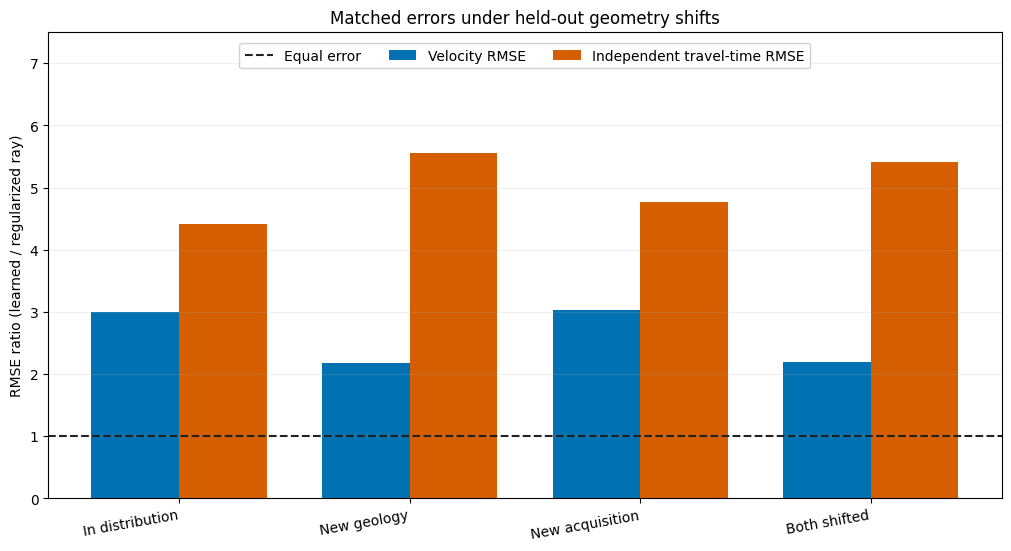

In [5]:
# Plot aggregate error ratios across all four held-out cohorts.
labels = {"id_test": "In distribution", "family_only": "New geology",
          "acquisition_only": "New acquisition", "joint_ood": "Both shifted"}
positions = np.arange(len(test_names))
velocity_ratio = [scores[name]["learned_to_classical_velocity_ratio"] for name in test_names]
time_ratio = [scores[name]["learned_to_classical_oracle_ratio"] for name in test_names]
fig, ax = plt.subplots(figsize=(10, 5.4), constrained_layout=True)
ax.bar(positions - 0.19, velocity_ratio, width=0.38, color="#0072B2", label="Velocity RMSE")
ax.bar(positions + 0.19, time_ratio, width=0.38, color="#D55E00", label="Independent travel-time RMSE")
ax.axhline(1, color="#222222", linestyle="--", label="Equal error")
ax.set_xticks(positions, [labels[name] for name in test_names], rotation=10, ha="right")
ax.set_ylim(0, max(velocity_ratio + time_ratio) * 1.35)
ax.set_ylabel("RMSE ratio (learned / regularized ray)")
ax.set_title("Matched errors under held-out geometry shifts")
ax.legend(frameon=True, framealpha=0.92, ncols=3, loc="upper center", bbox_to_anchor=(0.5, 0.99))
ax.grid(axis="y", alpha=0.2)
plt.show()

The joint-shift panel resolves the population behind the aggregate: each point is one paired realization, not an independent geology. Dotted boundaries mark equal errors. A lower-left point improves both metrics; other quadrants expose trade-offs or regressions.

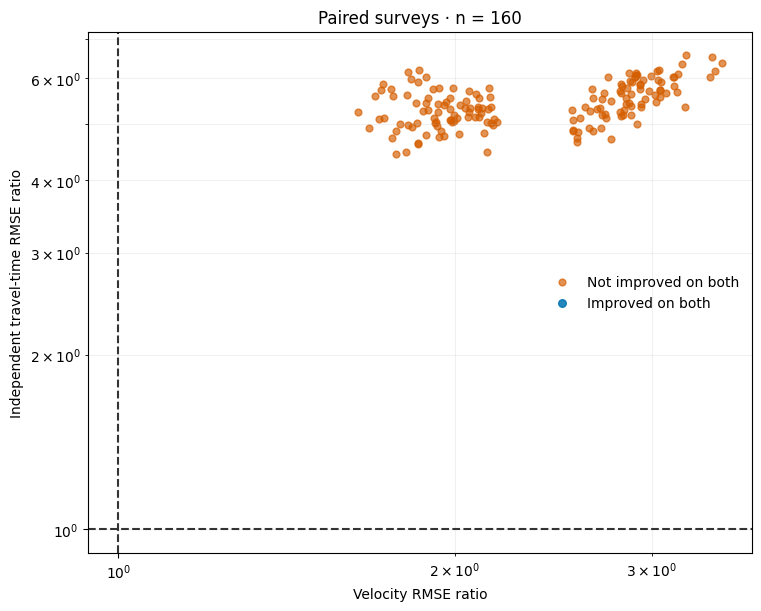

Improved on both: 0 of 160


In [6]:
# Each point pairs both error measures from one synthetic survey.
joint_scores = scores["joint_ood"]["per_record"]
velocity_pairs = np.asarray([row["learned_velocity_rmse_m_s"] / row["classical_velocity_rmse_m_s"] for row in joint_scores])
time_pairs = np.asarray([row["learned_oracle_rmse_ms"] / row["classical_oracle_rmse_ms"] for row in joint_scores])
both_improved = (velocity_pairs < 1) & (time_pairs < 1)
fig, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
ax.scatter(velocity_pairs[~both_improved], time_pairs[~both_improved], s=24, alpha=0.68, color="#D55E00", label="Not improved on both")
ax.scatter(velocity_pairs[both_improved], time_pairs[both_improved], s=30, alpha=0.85, color="#0072B2", label="Improved on both")
ax.axvline(1, color="#333333", linestyle="--")
ax.axhline(1, color="#333333", linestyle="--")
ax.set(xscale="log", yscale="log", xlabel="Velocity RMSE ratio", ylabel="Independent travel-time RMSE ratio", title="Paired surveys · n = 160")
ax.legend(frameon=False)
ax.grid(which="both", alpha=0.18)
plt.show()
print("Improved on both:", int(both_improved.sum()), "of", len(joint_scores))

## Results

**Answer:** No. The joint-shift velocity and independent travel-time RMSE ratios are 2.1875 and 5.4173; both exceed 1.0. The model loses to the regularized inversion on both declared measures. These cohorts are synthetic and do not quantify field accuracy.

## Summary

This notebook derives the residual feature, applies the saved CNN to regenerated held-out surveys and compares it with a validation-selected regularized ray inversion. The hypothesis is not supported: both aggregate ratios exceed one. The result is specific to a 16 × 16 straight-ray generator, its noise and survey layouts; it does not establish field or full-waveform FWI performance.

## References

1. Göppel, S., Frikel, J. and Haltmeier, M. (2023). *Data-proximal null-space networks for inverse problems*. [arXiv](https://arxiv.org/abs/2309.06573), [DOI: 10.48550/arXiv.2309.06573](https://doi.org/10.48550/arXiv.2309.06573).
2. LANL, [OpenFWI benchmark repository](https://github.com/lanl/OpenFWI); its data are not loaded here.
3. Reproducible implementation: `data-pipeline/velocity_physics_refinement.py`, `data-pipeline/velocity_validation.py` and `models/experimental/m12-physics-cuda-20261004/`.